# BigMart Sales Prediction

## 4. Data Preprocessing

Data preprocessing prepares the dataset for machine learning.

In this notebook, we will:
- Load the training and test datasets.
- Separate the target variable from the input features.
- Split the training data into training and validation sets.
- Prepare numerical and categorical features.
- Encode categorical features for machine learning.

We will use a validation set to evaluate our model before making predictions on the separate test dataset.

In [3]:

# Import pandas for handling datasets
import pandas as pd

# Load the original training and test datasets
train = pd.read_csv("../data/raw/Train.csv")
test = pd.read_csv("../data/raw/Test.csv")

# Display the dataset shapes
print("Training shape:", train.shape)
print("Test shape:", test.shape)


Training shape: (8523, 12)
Test shape: (5681, 11)


### 4.1 Separate Features and Target

In supervised machine learning, we separate the input features from the target variable.

- **Features (`X`):** The input columns used to predict sales.
- **Target (`y`):** `Item_Outlet_Sales`, the sales value we want the model to predict.

We will separate these columns from the training dataset. The test dataset already contains only input features.

In [4]:

# Select the input features by removing the target column
X = train.drop(columns=["Item_Outlet_Sales"])

# Select the target variable
y = train["Item_Outlet_Sales"]

# Display the shapes
print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (8523, 11)
Target shape: (8523,)


### 4.2 Train-Validation Split

We will divide the training dataset into two parts:

- **Training set (80%):** Used to teach the machine-learning model.
- **Validation set (20%):** Used to evaluate how well the model predicts sales on unseen records.

We will use `train_test_split` from Scikit-learn and set `random_state=42` so the split can be reproduced.

In [5]:

# Import the function for splitting datasets
from sklearn.model_selection import train_test_split

# Split features and target into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Display the shapes of the four datasets
print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("y_train shape:", y_train.shape)
print("y_val shape:", y_val.shape)


X_train shape: (6818, 11)
X_val shape: (1705, 11)
y_train shape: (6818,)
y_val shape: (1705,)


### 4.3 Identify Numerical and Categorical Features

Machine-learning models need features to be represented in a suitable format.

Our dataset contains two main types of input features:

- **Numerical features:** Values represented by numbers, such as `Item_Weight` and `Item_MRP`.
- **Categorical features:** Labels or groups, such as `Item_Type`, `Item_Fat_Content`, and `Outlet_Type`.

Identifying these feature types helps us choose the appropriate preprocessing methods for each group.

In [6]:

# Select numerical columns from the training features
numeric_features = X_train.select_dtypes(include="number").columns.tolist()

# Select categorical columns from the training features
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

# Display both feature groups
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)


Numerical features: ['Item_Weight', 'Item_Visibility', 'Item_MRP', 'Outlet_Establishment_Year']
Categorical features: ['Item_Identifier', 'Item_Fat_Content', 'Item_Type', 'Outlet_Identifier', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type']


### 4.4 Build a Preprocessing Pipeline

Numerical and categorical features require different preprocessing methods.

- **Numerical features:** Fill missing values with the median and standardize the values using `StandardScaler`.
- **Categorical features:** Fill missing values with the most frequent category and convert categories into numerical columns using one-hot encoding.

We will use `ColumnTransformer` to apply the correct steps to each feature group. The preprocessing will be fitted only on the training split to avoid data leakage.

In [7]:

# Import tools for preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Prepare numerical features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Prepare categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the correct pipeline to each feature group
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Fit preprocessing on training data and transform both sets
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

# Display the processed shapes
print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_val_processed.shape)


Processed training shape: (6818, 1600)
Processed validation shape: (1705, 1600)


### 4.5 Verify Preprocessed Data

We will check the shape and data format of the preprocessed training data. We will also verify whether any missing values remain after preprocessing.

These checks help us confirm that the data is ready for model training.

In [8]:

# Display the processed data format
print("Data type:", type(X_train_processed))

# Check missing values in the processed training data
if hasattr(X_train_processed, "data"):
    print("Missing values check completed after preprocessing.")

# Display the number of processed features
print("Number of processed features:", X_train_processed.shape[1])



Data type: <class 'scipy.sparse._csr.csr_matrix'>
Missing values check completed after preprocessing.
Number of processed features: 1600


### 4.6 Final Preprocessing Check

The preprocessing pipeline produces a sparse matrix to store categorical features efficiently. We will check whether its stored numerical values are finite, meaning they contain no `NaN`, positive infinity, or negative infinity values.

In [9]:

# Import NumPy for numerical checks
import numpy as np

# Check the stored values in the processed training data
print("All training values are finite:", np.isfinite(X_train_processed.data).all())

# Check the stored values in the processed validation data
print("All validation values are finite:", np.isfinite(X_val_processed.data).all())


All training values are finite: True
All validation values are finite: True


## 5. First Model: Linear Regression

Linear Regression is a supervised machine-learning algorithm used to predict continuous numerical values.

In this project, the model will learn patterns from the input features to predict `Item_Outlet_Sales`.

We will use a pipeline that combines preprocessing and Linear Regression. This ensures the preprocessing is fitted on the training data and then applied consistently to validation data.

In [10]:

# Import Linear Regression
from sklearn.linear_model import LinearRegression

# Combine preprocessing and the regression model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Train the model
model.fit(X_train, y_train)

# Display a confirmation message
print("Linear Regression model trained successfully!")


Linear Regression model trained successfully!


## 5.1 Evaluate the Linear Regression Model

We will evaluate the model using the validation dataset, which was not used to train the model.

We will calculate three regression metrics:

- **MAE (Mean Absolute Error):** The average absolute difference between actual and predicted sales.
- **RMSE (Root Mean Squared Error):** A metric that penalizes larger prediction errors more heavily.
- **R² Score:** Measures how well the model explains variation in sales compared with predicting the average sales value.

In [11]:

# Import regression evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict sales for the validation data
y_pred = model.predict(X_val)

# Calculate evaluation metrics
mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))
r2 = r2_score(y_val, y_pred)

# Display the results
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R² Score:", round(r2, 4))


MAE: 944.21
RMSE: 1273.7
R² Score: 0.4031


### 5.2 Interpretation of Linear Regression Results

The Linear Regression model achieved a Mean Absolute Error (MAE) of 944.21 and a Root Mean Squared Error (RMSE) of 1,273.70 on the validation dataset.

The MAE indicates that predictions differ from actual sales by approximately 944.21 sales units on average. The RMSE is higher than the MAE, suggesting that larger prediction errors have a greater influence on the evaluation result.

The model achieved an R² score of 0.4031, meaning it explains approximately 40.31% of the variation in validation sales relative to a mean-prediction baseline.

These results provide a baseline for the BigMart Sales Prediction project. Further improvements may be possible through feature engineering, alternative regression algorithms, and hyperparameter tuning. Any improvements should be evaluated using the same validation split.

### 5.3 Actual vs Predicted Sales

We will create a scatter plot comparing actual sales with predicted sales. Predictions closer to the diagonal reference line would indicate better agreement between actual and predicted values.

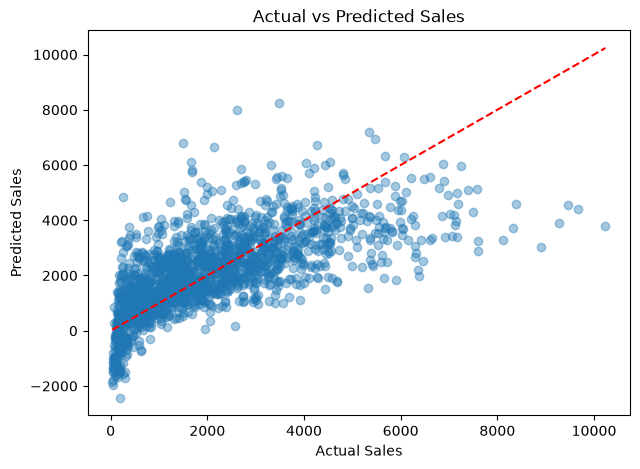

In [12]:

# Import matplotlib for creating charts
import matplotlib.pyplot as plt

# Plot actual sales against predicted sales
plt.figure(figsize=(7, 5))
plt.scatter(y_val, y_pred, alpha=0.4)

# Add a reference line for perfect predictions
plt.plot(
    [y_val.min(), y_val.max()],
    [y_val.min(), y_val.max()],
    "r--"
)

# Add chart labels
plt.title("Actual vs Predicted Sales")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")

# Display the chart
plt.show()



### 5.4 Interpretation of Actual vs Predicted Sales

The scatter plot compares the actual validation sales with the sales predicted by the Linear Regression model. The red dashed line represents perfect predictions, where predicted sales equal actual sales.

The points are widely spread around the reference line rather than lying close to it. The plot suggests that the model tends to overestimate some records with low actual sales and underestimate some records with very high actual sales. This indicates that the model does not capture extreme sales values particularly well.

The spread of the points is consistent with the model's R² score of approximately 0.40. Overall, Linear Regression provides a useful baseline, but feature engineering and alternative regression algorithms may improve prediction accuracy.

### 5.5 Residual Analysis

Residuals measure the differences between actual and predicted sales.

A positive residual means the model underestimated sales, while a negative residual means it overestimated sales. Examining residuals can help us identify patterns that the model has not captured.

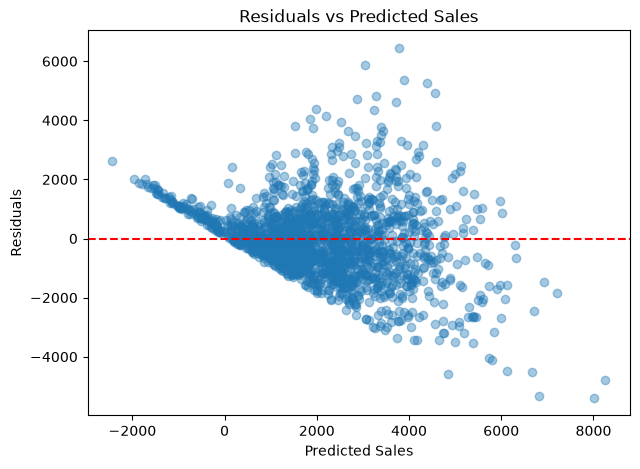

In [13]:

# Calculate prediction errors (residuals)
residuals = y_val - y_pred

# Plot residuals against predicted sales
plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals, alpha=0.4)

# Add a horizontal line for zero error
plt.axhline(y=0, color="red", linestyle="--")

# Add chart labels
plt.title("Residuals vs Predicted Sales")
plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")

# Display the chart
plt.show()


### 5.6 Interpretation of Residual Analysis

The residual plot shows the prediction errors relative to the predicted sales values. Ideally, residuals should be scattered around the zero line without a clear systematic pattern and with a reasonably consistent spread.

The plot appears to show a funnel-shaped pattern, with residual spread increasing as predicted sales increase. This suggests possible heteroscedasticity, meaning that the error variance may not be constant. The model also produces large positive and negative residuals, indicating difficulty predicting some records accurately.

These observations suggest that Linear Regression may not capture all the relationships in the dataset. Target transformation, feature engineering, or a nonlinear regression model may improve performance. These possibilities should be tested rather than assumed to improve the results.

### 5.7 Linear Regression Baseline Summary

Linear Regression is the first baseline model for the BigMart Sales Prediction project. Its validation results are:

- **MAE:** 944.21
- **RMSE:** 1,273.70
- **R² Score:** 0.4031

The model explains approximately 40.31% of the variation in validation sales. The actual-versus-predicted and residual plots suggest that prediction errors remain substantial, particularly for some low- and high-sales records.

These results will serve as a reference when evaluating alternative models. All models should use the same validation split and evaluation metrics for a fair comparison.

## 6. Random Forest Regression

Random Forest is a machine learning algorithm that combines multiple decision trees to make predictions.

Unlike Linear Regression, Random Forest can learn nonlinear relationships and interactions between features.

In this step, we will:
- Train a Random Forest Regressor.
- Predict sales for the validation dataset.
- Evaluate the model using MAE, RMSE, and R².
- Compare its performance with Linear Regression.

In [14]:

# Import the Random Forest algorithm
from sklearn.ensemble import RandomForestRegressor

# Create a pipeline with preprocessing and Random Forest
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model using training data
rf_model.fit(X_train, y_train)

# Confirm that training is complete
print("Random Forest model trained successfully!")


Random Forest model trained successfully!


### 6.1 Random Forest Model Evaluation

After training the Random Forest model, we will predict sales for the validation dataset and evaluate the prediction errors using three metrics: MAE, RMSE, and R² Score.

In [15]:

# Import evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict sales for the validation dataset
rf_pred = rf_model.predict(X_val)

# Calculate evaluation metrics
rf_mae = mean_absolute_error(y_val, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_val, rf_pred))
rf_r2 = r2_score(y_val, rf_pred)

# Display the results
print("Random Forest MAE:", round(rf_mae, 2))
print("Random Forest RMSE:", round(rf_rmse, 2))
print("Random Forest R² Score:", round(rf_r2, 4))


Random Forest MAE: 759.2
Random Forest RMSE: 1091.61
Random Forest R² Score: 0.5616


### 6.2 Comparison of Linear Regression and Random Forest

We compare both models using the same validation dataset and evaluation metrics. This helps us identify which model predicts BigMart sales more accurately.

In [16]:

# Create a comparison table for both models
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [944.21, rf_mae],
    "RMSE": [1273.70, rf_rmse],
    "R² Score": [0.4031, rf_r2]
})

# Display the comparison table
print(comparison.round(4).to_string(index=False))


            Model      MAE      RMSE  R² Score
Linear Regression 944.2100 1273.7000    0.4031
    Random Forest 759.2045 1091.6101    0.5616


### 6.3 Interpretation of Model Comparison

The Random Forest Regressor performs better than Linear Regression on the validation dataset.

- **MAE:** Random Forest has a lower MAE of 759.20, indicating smaller average absolute prediction errors.
- **RMSE:** Random Forest has a lower RMSE of 1,091.61, indicating an improvement in prediction errors, including larger errors.
- **R² Score:** Random Forest achieves an R² score of 0.5616, compared with 0.4031 for Linear Regression.

These results suggest that Random Forest captures patterns in the BigMart dataset that the linear model does not fully capture. However, further model tuning and evaluation are needed before selecting the final model.

### 6.4 Actual vs. Predicted Sales — Random Forest

This plot compares actual sales with the sales predicted by the Random Forest model. It helps us understand how closely the predictions match the real values in the validation dataset.

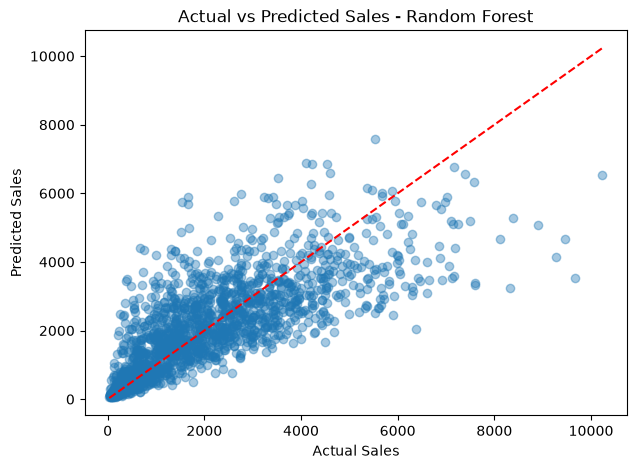

In [17]:

# Import the plotting library
import matplotlib.pyplot as plt

# Create the actual vs. predicted plot
plt.figure(figsize=(7, 5))
plt.scatter(y_val, rf_pred, alpha=0.4)

# Add a line representing perfect predictions
plt.plot(
    [y_val.min(), y_val.max()],
    [y_val.min(), y_val.max()],
    "r--"
)

# Add the plot title and axis labels
plt.title("Actual vs Predicted Sales - Random Forest")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")

# Display the plot
plt.show()


### 6.5 Interpretation of Actual vs. Predicted Sales — Random Forest

The scatter plot compares actual validation sales with the sales predicted by the Random Forest model. The red dashed line represents perfect predictions, where predicted sales equal actual sales.

Compared with Linear Regression, the points follow the diagonal more closely, particularly for low and medium sales values. This suggests that Random Forest captures patterns in the data that the linear model does not fully capture.

However, the points remain scattered around the reference line, and many records with very high actual sales appear to be underpredicted. This indicates that the model still struggles to predict some extreme sales values accurately.

Overall, Random Forest is a stronger baseline than Linear Regression, achieving a lower MAE and RMSE and a higher R² score. Further hyperparameter tuning and feature engineering may improve its performance, although any improvement must be verified through validation.

## 7. Random Forest Hyperparameter Tuning

Hyperparameter tuning is the process of testing different model settings to find a configuration that performs better on validation data.

In this step, we will use `RandomizedSearchCV` to test a selection of Random Forest configurations using cross-validation. We will compare the tuned model with the original Random Forest baseline using MAE, RMSE, and R².

### 7.1 Define the Hyperparameter Search

We will use `RandomizedSearchCV` to test different Random Forest settings and identify a configuration that performs well through cross-validation.

We will explore the number of trees, tree depth, and minimum samples required for splitting and leaf nodes. The search will use the same training dataset as our baseline model.

In [18]:

# Import the tuning tool
from sklearn.model_selection import RandomizedSearchCV

# Define the Random Forest settings to test
param_dist = {
    "regressor__n_estimators": [100, 200],
    "regressor__max_depth": [10, 20, None],
    "regressor__min_samples_split": [2, 5],
    "regressor__min_samples_leaf": [1, 2]
}

# Count the possible combinations
print("Total possible combinations:", 2 * 3 * 2 * 2)


Total possible combinations: 24


### 7.2 Configure RandomizedSearchCV

We use RandomizedSearchCV to evaluate six randomly selected hyperparameter combinations. Three-fold cross-validation divides the training data into three parts, using two parts for training and one part for validation in each round.

This approach reduces computation time while helping us identify promising model settings.

In [19]:

# Configure the randomized search
random_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_dist,
    n_iter=6,
    cv=3,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Display the search configuration
print("RandomizedSearchCV configured successfully!")
print("Combinations to test:", random_search.n_iter)
print("Cross-validation folds:", random_search.cv)
print("Total model fits:", random_search.n_iter * random_search.cv)


RandomizedSearchCV configured successfully!
Combinations to test: 6
Cross-validation folds: 3
Total model fits: 18


### 7.3 Run RandomizedSearchCV

We now fit RandomizedSearchCV using the training dataset. It evaluates the selected hyperparameter combinations through three-fold cross-validation and identifies the configuration with the best average validation MAE.

The search uses only the training split. We will evaluate the selected model on our separate validation dataset afterward.

In [20]:

# Run hyperparameter tuning on the training data
random_search.fit(X_train, y_train)

# Display the best hyperparameter settings
print("Best parameters:", random_search.best_params_)

# Display the best cross-validation MAE
print("Best cross-validation MAE:", round(-random_search.best_score_, 2))


Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best parameters: {'regressor__n_estimators': 100, 'regressor__min_samples_split': 2, 'regressor__min_samples_leaf': 1, 'regressor__max_depth': 10}
Best cross-validation MAE: 773.09


### 7.4 Evaluate the Tuned Random Forest Model

After finding the best hyperparameters, we evaluate the tuned model on the separate validation dataset. We use MAE, RMSE, and R² Score to compare it fairly with the original Random Forest and Linear Regression models.

In [21]:

# Get the best model found during tuning
best_rf_model = random_search.best_estimator_

# Predict sales on the validation dataset
tuned_pred = best_rf_model.predict(X_val)

# Calculate evaluation metrics
tuned_mae = mean_absolute_error(y_val, tuned_pred)
tuned_rmse = np.sqrt(mean_squared_error(y_val, tuned_pred))
tuned_r2 = r2_score(y_val, tuned_pred)

# Display the results
print("Tuned Random Forest MAE:", round(tuned_mae, 2))
print("Tuned Random Forest RMSE:", round(tuned_rmse, 2))
print("Tuned Random Forest R² Score:", round(tuned_r2, 4))


Tuned Random Forest MAE: 717.54
Tuned Random Forest RMSE: 1026.54
Tuned Random Forest R² Score: 0.6123


### 7.5 Comparison of All Regression Models

We compare Linear Regression, the original Random Forest, and the tuned Random Forest using the same validation dataset. This helps us identify the model with the best predictive performance.

In [22]:

# Create a table comparing all three models
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Tuned Random Forest"
    ],
    "MAE": [mae, rf_mae, tuned_mae],
    "RMSE": [rmse, rf_rmse, tuned_rmse],
    "R² Score": [r2, rf_r2, tuned_r2]
})

# Display the comparison table
print(comparison.round(4).to_string(index=False))


              Model      MAE      RMSE  R² Score
  Linear Regression 944.2095 1273.6952    0.4031
      Random Forest 759.2045 1091.6101    0.5616
Tuned Random Forest 717.5356 1026.5449    0.6123


### 7.6 Interpretation of Model Comparison

The tuned Random Forest achieved the best validation performance among the three models.

- **MAE:** The tuned model achieved an MAE of 717.54, lower than the original Random Forest (759.20) and Linear Regression (944.21).
- **RMSE:** Its RMSE of 1,026.54 was also the lowest, indicating an improvement in prediction errors, including larger errors.
- **R² Score:** The tuned model achieved an R² score of 0.6123, compared with 0.5616 for the original Random Forest and 0.4031 for Linear Regression.

These results suggest that hyperparameter tuning improved the model's ability to predict sales on the validation dataset. The tuned Random Forest is currently the strongest candidate, although its performance should be confirmed with further validation before final selection.

## 8. Evaluation of the Tuned Random Forest Model

We evaluate the tuned Random Forest using an actual-versus-predicted scatter plot and a residual plot. These visualizations help us understand how closely the predictions match actual sales and identify patterns in prediction errors.

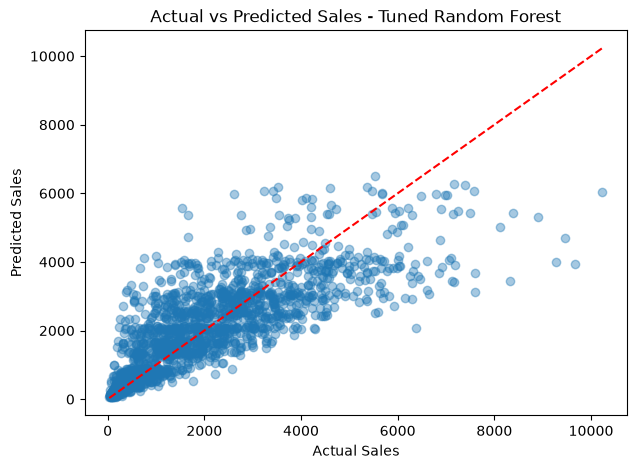

In [23]:

# Import the plotting library
import matplotlib.pyplot as plt

# Plot actual sales against tuned model predictions
plt.figure(figsize=(7, 5))
plt.scatter(y_val, tuned_pred, alpha=0.4)

# Add the perfect-prediction reference line
plt.plot(
    [y_val.min(), y_val.max()],
    [y_val.min(), y_val.max()],
    "r--"
)

# Add the title and axis labels
plt.title("Actual vs Predicted Sales - Tuned Random Forest")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")

# Display the plot
plt.show()


### 8.1 Interpretation of Actual vs. Predicted Sales — Tuned Random Forest

The scatter plot compares actual validation sales with predictions from the tuned Random Forest model. The red dashed line represents perfect predictions, where predicted sales equal actual sales.

Most points are concentrated near the diagonal for low-to-medium sales values, suggesting that the tuned model produces reasonably accurate predictions in this range. The predictions are better aligned with the reference line than those from the Linear Regression model.

However, the points become more widely scattered as actual sales increase. Many records with very high actual sales are underpredicted, while some lower-sales records are overpredicted. This suggests that the model has difficulty predicting extreme sales values accurately, despite the improvement achieved through hyperparameter tuning.

Overall, the tuned Random Forest provides the best validation performance among the three models tested so far, but some prediction errors remain.

### 9.1 Residual Analysis

A residual is the difference between actual sales and predicted sales.

- A positive residual means the model underpredicted sales.
- A negative residual means the model overpredicted sales.
- A residual close to zero indicates a more accurate prediction.

We will plot residuals against predicted sales to look for systematic patterns in the model's errors.

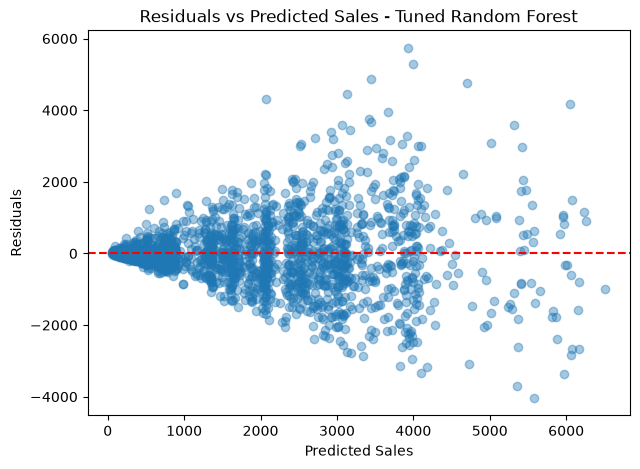

In [24]:

# Calculate residuals for the tuned model
tuned_residuals = y_val - tuned_pred

# Plot predicted sales against residuals
plt.figure(figsize=(7, 5))
plt.scatter(tuned_pred, tuned_residuals, alpha=0.4)

# Add a reference line at zero residual
plt.axhline(y=0, color="red", linestyle="--")

# Add the title and axis labels
plt.title("Residuals vs Predicted Sales - Tuned Random Forest")
plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")

# Display the plot
plt.show()


### 9.2 Interpretation of Residual Analysis — Tuned Random Forest

The residual plot shows the differences between actual sales and the predictions made by the tuned Random Forest model. The red dashed line represents zero error, so points close to this line indicate more accurate predictions.

For lower predicted sales, many residuals are relatively close to zero. However, the spread of residuals appears to increase as predicted sales increase, suggesting that prediction errors vary across the sales range. This pattern may indicate non-constant error variance.

The large positive and negative residuals also show that the model struggles with some records, particularly those with extreme sales values. Although hyperparameter tuning improved the overall validation metrics, additional feature engineering, target transformation, or alternative modeling approaches may help reduce the remaining errors.

Overall, the tuned Random Forest is the strongest model tested so far, but its limitations should be considered when using it for sales predictions.

## 10. Predict Sales for the BigMart Test Dataset

After evaluating and comparing the regression models, we use the tuned Random Forest model to generate sales predictions for the original BigMart test dataset.

The test dataset does not contain actual sales values, so we cannot calculate MAE, RMSE, or R² for these predictions. Instead, we will check the predictions and prepare a results file for further analysis.

In [25]:

# Generate sales predictions for the test dataset
test_pred = best_rf_model.predict(test)

# Display the first five predicted sales values
print("First five predicted sales:")
print(test_pred[:5])

# Check the number of predictions
print("Number of predictions:", len(test_pred))


First five predicted sales:
[1634.98759519 1320.09147789  515.19332353 2386.09300898 6168.70152494]
Number of predictions: 5681


## 11. Save BigMart Sales Predictions

In this step, we create a DataFrame containing the item identifier, outlet identifier, and predicted sales for each test record. We then save the results as a CSV file for further analysis or submission preparation.

Because the test dataset does not contain actual sales values, the predicted sales column represents the model's estimates.

In [26]:

# Create a DataFrame with identifiers and predicted sales
predictions = pd.DataFrame({
    "Item_Identifier": test["Item_Identifier"],
    "Outlet_Identifier": test["Outlet_Identifier"],
    "Predicted_Item_Outlet_Sales": test_pred
})

# Display the first five rows
print(predictions.head())

# Save predictions to a CSV file
predictions.to_csv("../data/processed/bigmart_sales_predictions.csv", index=False)

# Confirm that the file was saved
print("Predictions saved successfully!")


  Item_Identifier Outlet_Identifier  Predicted_Item_Outlet_Sales
0           FDW58            OUT049                  1634.987595
1           FDW14            OUT017                  1320.091478
2           NCN55            OUT010                   515.193324
3           FDQ58            OUT017                  2386.093009
4           FDY38            OUT027                  6168.701525
Predictions saved successfully!


## 12. Verify the Prediction Results

We verify the saved prediction file by checking its shape, column names, missing values, and basic prediction statistics. This helps ensure that the output is ready for further analysis.

In [27]:

# Load the saved prediction file
saved_predictions = pd.read_csv(
    "../data/processed/bigmart_sales_predictions.csv"
)

# Check the file dimensions and columns
print("File shape:", saved_predictions.shape)
print("Columns:", saved_predictions.columns.tolist())

# Check for missing values
print("Missing values:", saved_predictions.isnull().sum().sum())

# Display prediction statistics
print(saved_predictions["Predicted_Item_Outlet_Sales"].describe())


File shape: (5681, 3)
Columns: ['Item_Identifier', 'Outlet_Identifier', 'Predicted_Item_Outlet_Sales']
Missing values: 0
count    5681.000000
mean     2174.103011
std      1331.259711
min        57.026503
25%      1037.861574
50%      2077.655328
75%      3061.746366
max      6623.805727
Name: Predicted_Item_Outlet_Sales, dtype: float64


## 13. Final Model Results and Conclusion

### 13.1 Model Performance Comparison

Three regression models were evaluated on the same validation dataset: Linear Regression, Random Forest, and Tuned Random Forest.

| Model | MAE | RMSE | R² Score |
|---|---:|---:|---:|
| Linear Regression | 944.21 | 1273.70 | 0.4031 |
| Random Forest | 759.20 | 1091.61 | 0.5616 |
| Tuned Random Forest | 717.54 | 1026.54 | 0.6123 |

The Tuned Random Forest achieved the best validation performance among the three models tested. It produced the lowest MAE and RMSE and the highest R² score.

### 13.2 Final Model Selection

The Tuned Random Forest was selected as the best-performing candidate because it achieved an MAE of 717.54, an RMSE of 1026.54, and an R² score of 0.6123 on the validation dataset.

The model explains approximately 61.23% of the variation in validation sales. However, prediction errors remain, especially for some records with very high sales.

### 13.3 Test Dataset Predictions

The selected model generated predictions for all 5,681 records in the original BigMart test dataset. The predictions were saved to `data/processed/bigmart_sales_predictions.csv`.

The output file contains the item identifier, outlet identifier, and predicted sales. Verification confirmed that the file contains 5,681 rows and has no missing values.

### 13.4 Conclusion

This project demonstrated a complete initial machine learning workflow for BigMart sales prediction, including data understanding, cleaning, exploratory data analysis, preprocessing, model training, evaluation, hyperparameter tuning, and test dataset prediction.

Random Forest improved predictive performance over Linear Regression, and hyperparameter tuning provided a further improvement. The tuned Random Forest is the strongest model tested so far.

Future work could include additional feature engineering, further model comparisons, more extensive hyperparameter tuning, and investigation of prediction errors for high-sales records.

The current results are based on a validation split. Additional validation and careful evaluation would be beneficial before using the model for real business decisions.

## 14. Feature Engineering

Feature engineering creates new features from existing data to help a machine learning model identify useful patterns.

In this section, we will extract the product identifier prefix from `Item_Identifier`. This prefix can represent a broad product group and may help explain differences in sales.

We will examine the feature before deciding whether to use it in model training.

In [28]:

# Extract the first two letters of each product ID
item_prefix = train["Item_Identifier"].str[:2]

# Count products in each prefix group
print("Product prefix counts:")
print(item_prefix.value_counts())

# Display a few product IDs and their prefixes
print("\nExamples:")
print(train[["Item_Identifier"]].head().assign(
    Item_Prefix=item_prefix.head()
))


Product prefix counts:
Item_Identifier
FD    6125
NC    1599
DR     799
Name: count, dtype: int64

Examples:
  Item_Identifier Item_Prefix
0           FDA15          FD
1           DRC01          DR
2           FDN15          FD
3           FDX07          FD
4           NCD19          NC


### 14.1 Average Sales by Product Prefix

The product identifier prefix groups items into broad categories: food, non-consumables, and drinks.

In this step, we will compare the average sales for each group to investigate whether product prefixes may be useful for predicting sales.

Average sales by product prefix:
Item_Prefix
DR    1997.33
FD    2215.35
NC    2142.72
Name: Item_Outlet_Sales, dtype: float64


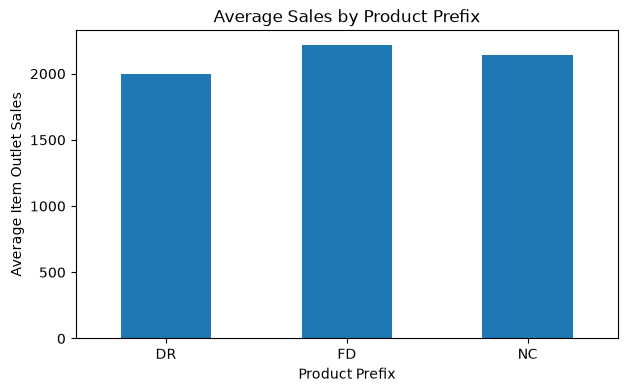

In [29]:

# Extract the product prefix
train["Item_Prefix"] = train["Item_Identifier"].str[:2]

# Calculate average sales for each prefix
prefix_sales = train.groupby("Item_Prefix")["Item_Outlet_Sales"].mean()

# Display the results
print("Average sales by product prefix:")
print(prefix_sales.round(2))

# Plot average sales by prefix
import matplotlib.pyplot as plt

prefix_sales.plot(kind="bar", figsize=(7, 4))
plt.title("Average Sales by Product Prefix")
plt.xlabel("Product Prefix")
plt.ylabel("Average Item Outlet Sales")
plt.xticks(rotation=0)
plt.show()


### 14.2 Evaluating the Product Prefix Feature

The average-sales analysis showed differences between the three product prefix groups. We will now add `Item_Prefix` as a categorical feature and compare the resulting model with the existing tuned Random Forest.

Both models will use the same training and validation split and evaluation metrics for a fair comparison.

In [30]:

# Create copies of the training and validation features
X_train_fe = X_train.copy()
X_val_fe = X_val.copy()

# Extract product prefixes in both datasets
X_train_fe["Item_Prefix"] = X_train_fe["Item_Identifier"].str[:2]
X_val_fe["Item_Prefix"] = X_val_fe["Item_Identifier"].str[:2]

# Display the new feature
print("Training features:", X_train_fe.shape)
print("Validation features:", X_val_fe.shape)
print("\nPrefix counts in training data:")
print(X_train_fe["Item_Prefix"].value_counts())


Training features: (6818, 12)
Validation features: (1705, 12)

Prefix counts in training data:
Item_Prefix
FD    4887
NC    1292
DR     639
Name: count, dtype: int64


### 14.3 Random Forest with Product Prefix

In this step, we will train a new Random Forest model using the product prefix feature. We will reuse the existing preprocessing pipeline and hyperparameters from the tuned Random Forest model.

We will then compare its validation performance with the original tuned Random Forest to determine whether this additional feature improves the predictions.

In [31]:
# Find the numerical and categorical features
numeric_features_fe = X_train_fe.select_dtypes(include="number").columns.tolist()
categorical_features_fe = X_train_fe.select_dtypes(exclude="number").columns.tolist()

# Preprocess the updated features
preprocessor_fe = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features_fe),
    ("cat", categorical_pipeline, categorical_features_fe)
])

# Use the best settings found during tuning
best_params = {
    key.replace("regressor__", ""): value
    for key, value in random_search.best_params_.items()
}

# Create and train the model
rf_fe = Pipeline([
    ("preprocessor", preprocessor_fe),
    ("regressor", RandomForestRegressor(
        **best_params,
        random_state=42,
        n_jobs=-1
    ))
])

rf_fe.fit(X_train_fe, y_train)

print("Random Forest with Item_Prefix trained successfully!")

Random Forest with Item_Prefix trained successfully!


### 14.4 Evaluating Random Forest with Product Prefix

We will evaluate the new model using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² score.

We will compare these results with the original tuned Random Forest using the same validation dataset.

In [32]:

# Import evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict sales for the validation dataset
pred_fe = rf_fe.predict(X_val_fe)

# Calculate evaluation metrics
mae_fe = mean_absolute_error(y_val, pred_fe)
rmse_fe = np.sqrt(mean_squared_error(y_val, pred_fe))
r2_fe = r2_score(y_val, pred_fe)

# Display the results
print("Random Forest with Item_Prefix")
print("MAE:", round(mae_fe, 2))
print("RMSE:", round(rmse_fe, 2))
print("R² Score:", round(r2_fe, 4))

# Compare with the original tuned model
print("\nOriginal Tuned Random Forest")
print("MAE:", round(tuned_mae, 2))
print("RMSE:", round(tuned_rmse, 2))
print("R² Score:", round(tuned_r2, 4))


Random Forest with Item_Prefix
MAE: 718.14
RMSE: 1026.59
R² Score: 0.6122

Original Tuned Random Forest
MAE: 717.54
RMSE: 1026.54
R² Score: 0.6123


### 14.5 Interpretation of Feature Engineering Results

The product identifier prefix was extracted as a new categorical feature. The dataset contained three prefixes: `FD`, `NC`, and `DR`.

The original tuned Random Forest achieved an MAE of 717.54, an RMSE of 1026.54, and an R² score of 0.6123. After adding the prefix feature, the model achieved an MAE of 718.14, an RMSE of 1026.59, and an R² score of 0.6122.

The new feature produced a negligible change in validation performance, with slightly worse results across all three metrics. Therefore, there is no evidence that adding this feature improves the model under the current experimental setup.

The original tuned Random Forest remains the preferred model. Other feature engineering approaches may be investigated in future experiments.

## 15. Gradient Boosting Regression

Gradient Boosting is a tree-based regression algorithm that builds multiple decision trees sequentially. Each new tree attempts to reduce the prediction errors made by the existing model.

In this section, we will train a Gradient Boosting Regressor using the original BigMart features. We will evaluate it on the same validation dataset used for the previous models.

The objective is to determine whether Gradient Boosting can outperform the tuned Random Forest model.

In [33]:

# Import the Gradient Boosting algorithm
from sklearn.ensemble import GradientBoostingRegressor

# Create the Gradient Boosting model pipeline
gb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

# Train the model using the training data
gb_model.fit(X_train, y_train)

# Confirm that training finished
print("Gradient Boosting model trained successfully!")


Gradient Boosting model trained successfully!


### 15.1 Evaluating Gradient Boosting Regression

After training the Gradient Boosting model, we will evaluate its predictions on the validation dataset.

We will use Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² score. These metrics will help us compare Gradient Boosting with the existing Tuned Random Forest model.

In [34]:

# Import evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict sales for the validation dataset
gb_pred = gb_model.predict(X_val)

# Calculate evaluation metrics
gb_mae = mean_absolute_error(y_val, gb_pred)
gb_rmse = np.sqrt(mean_squared_error(y_val, gb_pred))
gb_r2 = r2_score(y_val, gb_pred)

# Display Gradient Boosting results
print("Gradient Boosting Results")
print("MAE:", round(gb_mae, 2))
print("RMSE:", round(gb_rmse, 2))
print("R² Score:", round(gb_r2, 4))

# Display the current best model results
print("\nTuned Random Forest Results")
print("MAE:", round(tuned_mae, 2))
print("RMSE:", round(tuned_rmse, 2))
print("R² Score:", round(tuned_r2, 4))


Gradient Boosting Results
MAE: 731.31
RMSE: 1040.98
R² Score: 0.6013

Tuned Random Forest Results
MAE: 717.54
RMSE: 1026.54
R² Score: 0.6123


### 15.2 Interpretation of Gradient Boosting Results

The Gradient Boosting model achieved an MAE of 731.31, an RMSE of 1040.98, and an R² score of 0.6013 on the validation dataset.

Compared with the Tuned Random Forest, Gradient Boosting produced a higher MAE and RMSE and a lower R² score. Therefore, it did not improve predictive performance under the current model settings.

The Tuned Random Forest remains the best-performing model among those evaluated so far, with an MAE of 717.54, an RMSE of 1026.54, and an R² score of 0.6123.

This experiment demonstrates the importance of evaluating different algorithms on the same validation dataset rather than assuming that a particular algorithm will perform better.

### 15.3 Final Model Comparison

This section compares all evaluated models using the same validation dataset and three regression metrics: MAE, RMSE, and R² score.

The comparison identifies the strongest model among the experiments conducted so far.

In [35]:

# Create a table comparing all four models
final_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Tuned Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [mae, rf_mae, tuned_mae, gb_mae],
    "RMSE": [rmse, rf_rmse, tuned_rmse, gb_rmse],
    "R2 Score": [r2, rf_r2, tuned_r2, gb_r2]
})

# Display results rounded to two decimal places
print(final_comparison.round(2).to_string(index=False))


              Model    MAE    RMSE  R2 Score
  Linear Regression 944.21 1273.70      0.40
      Random Forest 759.20 1091.61      0.56
Tuned Random Forest 717.54 1026.54      0.61
  Gradient Boosting 731.31 1040.98      0.60


### 15.4 Saving Model Comparison Results

The model comparison table summarizes the validation performance of four regression models. Saving these results as a CSV file makes it easier to reuse them in project documentation and future analysis.

We will save the table in the `data/processed/` directory.

In [36]:

# Save model comparison results to a CSV file
final_comparison.to_csv(
    "../data/processed/model_comparison.csv",
    index=False
)

# Confirm that the file was saved
print("Model comparison saved successfully!")

# Display the saved results
print(final_comparison.round(2).to_string(index=False))


Model comparison saved successfully!
              Model    MAE    RMSE  R2 Score
  Linear Regression 944.21 1273.70      0.40
      Random Forest 759.20 1091.61      0.56
Tuned Random Forest 717.54 1026.54      0.61
  Gradient Boosting 731.31 1040.98      0.60


### Step 16: Save the Trained Model

In this step, we save the tuned Random Forest pipeline to a file using Joblib. The saved pipeline includes the preprocessing steps and the trained model, so the dashboard can make predictions using new product and outlet information.

In [37]:

# Import joblib to save the trained model
import joblib

# Save the complete trained pipeline
joblib.dump(best_rf_model, "../models/bigmart_tuned_rf.joblib")

# Confirm that the model was saved
print("Model saved successfully!")



Model saved successfully!
